<a href="https://colab.research.google.com/github/SharikaTasnim23/Thesis/blob/main/Shared%2BAugmented.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Cell 1: Environment and Libraries Setup
!pip install librosa pandas numpy tensorflow scikit-learn

import os
import re
import librosa
import numpy as np
import pandas as pd
import tensorflow as tf
import random
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, accuracy_score, f1_score

# রেজাল্টের পুনরাবৃত্তি ঠিক রাখতে সিড সেট করা
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)
# জিপিইউ অপারেশনকে যতটা সম্ভব ডিটারমিনিস্টিক করা
tf.config.experimental.enable_op_determinism()

print("TensorFlow Version:", tf.__version__)
print("Cell 1: Environment is ready!")

TensorFlow Version: 2.20.0
Cell 1: Environment is ready!


In [ ]:
# Cell 2: Global Constants and Paths
from google.colab import drive
drive.mount('/content/drive')

CSV_PATH = "/content/drive/MyDrive/Wolfset_Dataset/Wolfset_Audio_files/Wolfset_Index.csv"
AUDIO_DIR = "/content/drive/MyDrive/Wolfset_Dataset/Wolfset_Audio_files"

# অডিও প্রসেসিং প্যারামিটার
SR = 22050                 # মোটর ও শিপিং নয়েজের জন্য আদর্শ স্যাম্পলিং রেট
SEGMENT_SEC = 10            # ৩ সেকেন্ডের উইন্ডো সাইজ
SEGMENT_SAMPLES = SR * SEGMENT_SEC

# ফিচার এক্সট্র্যাকশন প্যারামিটার (টোটাল ১৭৪টি ফিচার আসবে)
N_FFT = 2048               # ফ্রিকোয়েন্সি রেজোলিউশন বাড়ানোর জন্য বড় উইন্ডো
HOP_LENGTH = 512           # ৭৫% ইন্টারনাল ওভারল্যাপ
N_MELS = 128               # ১২৮টি মেল ব্যান্ড
N_MFCC = 40                # ৪০টি এমএফসিসি কোফিসিয়েন্ট
N_BANDS = 6                # ৬টি স্পেকট্রাল কনট্রাস্ট ব্যান্ড

# টোটাল ফিচার = (১২৮ মেল + ৪০ এমএফসিসি + ৬ কনট্রাস্ট) = ১৭৪ (Mean) + ১৭৪ (Std) = ৩৪৮
print(f"Target Feature Vector Size per segment: { (N_MELS + N_MFCC + N_BANDS) * 2 } (348, 1)")

Mounted at /content/drive
Target Feature Vector Size per segment: 348 (348, 1)


In [ ]:
# Cell 3: Structural File Name Parsing using Regex Pattern
FILENAME_PATTERN = r"^[AE](\d{5})T\d{2}N\d{2}(?:x\d+)?"

# ৫টি মোটরের জন্য খালি লিস্ট তৈরি
motor_targets = {f"Motor_{i}": [] for i in range(1, 6)}
valid_rows = []
base_sessions = []

df_raw = pd.read_csv(CSV_PATH)

for idx, row in df_raw.iterrows():
    filename = str(row['File Name'])
    match = re.match(FILENAME_PATTERN, filename)

    if match:
        state_digits = match.group(1) # ৫ ডিজিটের কোড এক্সট্র্যাক্ট করা (যেমন: '13201')

        for i in range(5):
            motor_targets[f"Motor_{i+1}"].append(int(state_digits[i]))

        base_session = filename.split('x')[0] # ডাটা লিক বন্ধ করতে বেস সেশন আইডি নেওয়া
        base_sessions.append(base_session)
        valid_rows.append(idx)

# পার্স করা লেবেল দিয়ে পরিচ্ছন্ন মেটাডাটা ফ্রেম তৈরি
metadata_df = df_raw.iloc[valid_rows].copy()
metadata_df['Base_Session_ID'] = base_sessions
for motor_name, labels in motor_targets.items():
    metadata_df[motor_name] = labels

print(f"Parsing complete! Valid audio files for processing: {len(metadata_df)}")

Parsing complete! Valid audio files for processing: 168


In [ ]:
# =============================================================
# Cell 3.5: Filter Distractor Classes (Pure Background) 46 samples
# =============================================================

# আপনার মূল ডেটাফ্রেমের নাম যদি 'df' হয়ে থাকে:
df = metadata_df[metadata_df['Description\n(Targets)'] != 'Absent (or disconnected)'].reset_index(drop=True)

print(f"Data filtered successfully! Remaining samples for feature extraction: {len(df)}")

Data filtered successfully! Remaining samples for feature extraction: 122


In [ ]:
# Cell 4: Audio Preprocessing and Feature Extraction (Mean + Std Version)

def filter_active_audio(y, top_db=20):
    """রেকর্ডিংয়ের শুরু/শেষ এবং মাঝখানের সম্পূর্ণ নীরব অংশ কেটে বাদ দেয়।"""
    intervals = librosa.effects.split(y, top_db=top_db)
    if len(intervals) == 0:
        return np.array([])
    return np.concatenate([y[start:end] for start, end in intervals])

def extract_combined_features(y_chunk, sr):
    """১০ সেকেন্ডের অ디오 চাঙ্ক থেকে Mean এবং Std বের করে ৩৪৮ সাইজের ভেক্টর বানায়।"""
    # ১. Mel-Spectrogram এক্সট্র্যাকশন
    mel = librosa.feature.melspectrogram(y=y_chunk, sr=sr, n_mels=N_MELS, n_fft=N_FFT, hop_length=HOP_LENGTH)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    mel_mean = np.mean(mel_db, axis=1, keepdims=True)
    mel_std = np.std(mel_db, axis=1, keepdims=True) # স্ট্যান্ডার্ড ডেভিয়েশন

    # ২. MFCCs এক্সট্র্যাকশন
    mfcc = librosa.feature.mfcc(y=y_chunk, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH)
    mfcc_mean = np.mean(mfcc, axis=1, keepdims=True)
    mfcc_std = np.std(mfcc, axis=1, keepdims=True) # স্ট্যান্ডার্ড ডেভিয়েশন

    # ৩. Spectral Contrast এক্সট্র্যাকশন
    contrast = librosa.feature.spectral_contrast(y=y_chunk, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_bands=N_BANDS)
    contrast_mean = np.mean(contrast[:N_BANDS], axis=1, keepdims=True)
    contrast_std = np.std(contrast[:N_BANDS], axis=1, keepdims=True) # স্ট্যান্ডার্ড ডেভিয়েশন

    # সব Mean এবং Std আলাদা আলাদা স্ট্যাক করা
    fused_mean = np.vstack([mel_mean, mfcc_mean, contrast_mean]) # (174, 1)
    fused_std = np.vstack([mel_std, mfcc_std, contrast_std])   # (174, 1)

    # চূড়ান্ত ভার্টিকাল স্ট্যাক (Mean + Std) -> (348, 1)
    fused = np.vstack([fused_mean, fused_std])
    return fused

In [ ]:
# Cell 5: Smart Feature Extraction with Auto-Save and Fast-Load Pipeline
import os
import numpy as np
import pandas as pd

# ১. ফিচার সেভ করার জন্য ড্রাইভের পাথ নির্ধারণ (Cell 2 এর AUDIO_DIR এর ভেতরেই সেভ হবে)
FEATURES_SAVE_PATH = os.path.join(os.path.dirname(AUDIO_DIR), "wolfset_348_features.npy")
METADATA_SAVE_PATH = os.path.join(os.path.dirname(AUDIO_DIR), "wolfset_segmented_metadata_348_features.csv")

# মাল্টি-টাস্ক ইমব্যালেন্স হ্যান্ডেল করার লজিক (ওভারল্যাপ ফাংশন)
def calculate_multitask_overlap(row):
    motor_states = [row[f"Motor_{i}"] for i in range(1, 6)]
    if any(state >= 3 for state in motor_states):
        return 0.90  # রেয়ার মোটর কন্ডিশন থাকলে ৯০% ওভারল্যাপ
    return 0.0

# ২. চেক করা হচ্ছে ড্রাইভে অলরেডি ফিচার ফাইল দুটি আছে কিনা
if os.path.exists(FEATURES_SAVE_PATH) and os.path.exists(METADATA_SAVE_PATH):
    print("="*60)
    print("PRE-EXTRACTED FEATURES FOUND! LOADING FROM GOOGLE DRIVE...")
    print("="*60)

    # ড্রাইভ থেকে সরাসরি লোড করা (সময় লাগবে মাত্র ২-৩ সেকেন্ড!)
    X_features = np.load(FEATURES_SAVE_PATH).astype(np.float32)
    final_meta_df = pd.read_csv(METADATA_SAVE_PATH)

    print(f"✓ Success: Loaded Feature Matrix Shape: {X_features.shape}")
    print(f"✓ Success: Loaded Segmented Metadata Rows: {len(final_meta_df)}")

else:
    print("="*60)
    print("NO PRE-SAVED FEATURES FOUND. STARTING AUDIO PROCESSING LOOP...")
    print("  (This will take time on the first run, but will save for future runs)")
    print("="*60)

    all_features = []
    segmented_metadata = []
    segment_idx = 1

    for idx, row in metadata_df.iterrows():
        filename = row['File Name']
        filepath = os.path.join(AUDIO_DIR, filename)

        if not os.path.exists(filepath):
            continue

        try:
            y, _ = librosa.load(filepath, sr=SR)
            y_active = filter_active_audio(y, top_db=20)

            if len(y_active) < SEGMENT_SAMPLES:
                continue

            overlap = calculate_multitask_overlap(row)
            step_samples = int(SEGMENT_SAMPLES * (1.5 - overlap))

            for start in range(0, len(y_active) - SEGMENT_SAMPLES + 1, step_samples):
                y_chunk = y_active[start:start + SEGMENT_SAMPLES]
                features = extract_combined_features(y_chunk, SR)

                all_features.append(features)

                record = {
                    "Segment_ID": f"SEG_{segment_idx:05d}",
                    "Source_File_ID": filename,
                    "Base_Session_ID": row['Base_Session_ID']
                }
                for i in range(1, 6):
                    record[f"Motor_{i}"] = row[f"Motor_{i}"]
                segmented_metadata.append(record)
                segment_idx += 1

        except Exception as e:
            print(f"Error processing {filename}: {e}")

    # নম্পাই অ্যারে এবং পান্ডাস ডেটাফ্রেমে রূপান্তর
    X_features = np.array(all_features).astype(np.float32)
    final_meta_df = pd.DataFrame(segmented_metadata)

    # ৩. ভবিষ্যৎ রানগুলোর সময় বাঁচানোর জন্য ড্রাইভে পাকাপাকিভাবে সেভ করে রাখা
    print("\n Saving extracted features to Google Drive for future instant-loading...")
    np.save(FEATURES_SAVE_PATH, X_features)
    final_meta_df.to_csv(METADATA_SAVE_PATH, index=False)

    print(f"✓ Feature Extraction & Saving Complete! Shape: {X_features.shape}")

PRE-EXTRACTED FEATURES FOUND! LOADING FROM GOOGLE DRIVE...
✓ Success: Loaded Feature Matrix Shape: (1665, 348, 1)
✓ Success: Loaded Segmented Metadata Rows: 1665


In [ ]:
# ==============================================================================
# FIXED CONFIG B (CELL 6): Pure Synchronous Oversampling Cross-Validation Loop
# Fixed: Wiped out aggressive capping bug & resolved TF retracing warnings
# ==============================================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score

# --- ১. রিপ্রোডাক্টিবিলিটি লক করা ---
SEED = 42
def lock_experiment_seeds(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

lock_experiment_seeds(SEED)

N_SPLITS = 4
GROUP_COL = "Base_Session_ID"
MOTOR_COLS = [f"Motor_{i}" for i in range(1, 6)]
RESULT_DIR = "/content/drive/MyDrive/Wolfset_Dataset/Results/shared_backbone_config_B_ablation"
os.makedirs(RESULT_DIR, exist_ok=True)

# ডাটা এবং শেপ এলাইনমেন্ট (Inherited from Cell 5)
X_global = np.asarray(X_features).astype(np.float32)
X_global_cnn = np.expand_dims(X_global, axis=-1) if len(X_global.shape) == 2 else X_global
groups_global = final_meta_df[GROUP_COL].values

# লেবেল এনকোডার লকিং
label_encoders = {}
Y_encoded = {}
num_classes_per_motor = []

for motor in MOTOR_COLS:
    enc = LabelEncoder()
    Y_encoded[motor] = enc.fit_transform(final_meta_df[motor].astype(int).values)
    label_encoders[motor] = enc
    num_classes_per_motor.append(len(enc.classes_))

combo_labels = final_meta_df[MOTOR_COLS].astype(str).agg("_".join, axis=1).values
combo_encoder = LabelEncoder()
combo_y = combo_encoder.fit_transform(combo_labels)

# --- ২. বিশুদ্ধ সিনক্রোনাস আপ-স্যাম্পলিং + অগমেন্টেশন পাইপলাইন ---
def synchronous_resample_pipeline(X_train_raw, Y_train_raw, target_count=140, noise_factor=0.005, jitter_range=2):
    """
    টাওয়ার মডেলের মতো বিশুদ্ধ সিনক্রোনাস আপ-স্যাম্পলিং মেথড।
    মাইনোরিটি ক্লাসকে ১৪০ এ নিয়ে যাবে এবং মেজরিটি ক্লাসকে স্বাভাবিকভাবে কো-অকারেন্সের সুযোগ দেবে।
    """
    balanced_indices = list(range(len(X_train_raw)))

    for motor in MOTOR_COLS:
        y_motor = Y_train_raw[motor]
        for state in np.unique(y_motor):
            # বর্তমানে পুলে থাকা ইনডেক্সগুলোর ওপর ভিত্তি করে কাউন্ট করা
            current_count = np.sum(np.array([Y_train_raw[motor][i] for i in balanced_indices]) == state)
            if current_count < target_count:
                needed = target_count - current_count
                state_indices = np.where(y_motor == state)[0]
                if len(state_indices) > 0:
                    cloned = np.random.choice(state_indices, size=needed, replace=True)
                    balanced_indices.extend(cloned)

    X_bal = X_train_raw[balanced_indices].copy()
    Y_bal = {motor: Y_train_raw[motor][balanced_indices].copy() for motor in MOTOR_COLS}

    # শুধুমাত্র নতুন উৎপন্ন সিন্থেটিক ডেটায় জিটার এবং নয়েজ প্রয়োগ
    num_original = len(X_train_raw)
    if len(X_bal) > num_original:
        noise = np.random.normal(0, noise_factor, size=X_bal[num_original:].shape).astype(np.float32)
        X_bal[num_original:] += noise
        for i in range(num_original, len(X_bal)):
            shift = np.random.randint(-jitter_range, jitter_range + 1)
            X_bal[i] = np.roll(X_bal[i], shift, axis=0)

    return X_bal, Y_bal

# --- ৩. ডিফেন্সিভ গ্রুপ শিফটিং ---
def defensive_group_shift(train_idx, val_idx):
    train_idx, val_idx = list(train_idx), list(val_idx)
    for motor in MOTOR_COLS:
        y_all = Y_encoded[motor]
        global_states = set(np.unique(y_all))
        train_states = set(np.unique(y_all[train_idx]))
        missing_states = global_states - train_states

        for missing_state in missing_states:
            state_indices = np.where(y_all == missing_state)[0]
            missing_groups = np.unique(groups_global[state_indices])
            for group in missing_groups:
                group_indices = np.where(groups_global == group)[0]
                for idx in group_indices:
                    if idx in val_idx: val_idx.remove(idx)
                    if idx not in train_idx: train_idx.append(idx)
    return np.array(train_idx), np.array(val_idx)

# --- ৪. বেসলাইন আর্কিটেকচার বিল্ডার ---
def build_baseline_shared_backbone(input_shape, class_counts):
    inputs = tf.keras.Input(shape=input_shape, name="Acoustic_Input")
    x = tf.keras.layers.Conv1D(64, kernel_size=3, activation="relu", padding="same", name="Conv1D_1")(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling1D(pool_size=2)(x)

    x = tf.keras.layers.Conv1D(128, kernel_size=3, activation="relu", padding="same", name="Conv1D_2")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling1D(pool_size=2)(x)

    x = tf.keras.layers.Conv1D(256, kernel_size=3, activation="relu", padding="same", name="Conv1D_3")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling1D(pool_size=2)(x)

    x = tf.keras.layers.Flatten()(x)
    shared_features = tf.keras.layers.Dense(128, activation="relu", name="Shared_Dense")(x)
    shared_features = tf.keras.layers.Dropout(0.5)(shared_features)

    outputs = {}
    for i, num_classes in enumerate(class_counts):
        outputs[f"Motor_{i+1}"] = tf.keras.layers.Dense(num_classes, activation="softmax", name=f"Motor_{i+1}")(shared_features)

    return tf.keras.Model(inputs=inputs, outputs=outputs, name="Config_B_Fixed_Model")

# --- ৫. ৪-ফোল্ড ইটারেশন এক্সিকিউশন ---
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
pooled_true = {motor: [] for motor in MOTOR_COLS}
pooled_pred = {motor: [] for motor in MOTOR_COLS}

print("="*80)
print("RUNNING CONFIG B: FIXED SYNCHRONOUS OVERSAMPLING PIPELINE")
print("="*80)

for fold, (raw_train_idx, raw_val_idx) in enumerate(sgkf.split(X_global_cnn, combo_y, groups=groups_global)):
    print(f"\n⚡ Processing Fold {fold + 1}/{N_SPLITS} ⚡")

    train_idx, val_idx = defensive_group_shift(raw_train_idx, raw_val_idx)

    X_tr_raw, X_va_raw = X_global_cnn[train_idx], X_global_cnn[val_idx]
    Y_tr_raw = {motor: Y_encoded[motor][train_idx] for motor in MOTOR_COLS}
    Y_va_raw = {motor: Y_encoded[motor][val_idx] for motor in MOTOR_COLS}

    # বিশুদ্ধ রিস্যাম্পলিং রান
    X_tr_bal, Y_tr_bal = synchronous_resample_pipeline(X_tr_raw, Y_tr_raw, target_count=140)

    # ফোল্ড ১ এর ওপর ট্র্যাকিং প্রিন্ট (ভেরিফিকেশনের জন্য)
    if fold == 0:
        print("\n📊 FIXED BACKGROUND SAMPLES DISTRIBUTION (Fold 1 Output):")
        print(f"{'Motor Head':<12} | {'State ID':<10} | {'Before (Raw)':<12} | {'After (Balanced)':<18}")
        print("-"*60)
        for motor in MOTOR_COLS:
            for enc_state in range(len(label_encoders[motor].classes_)):
                orig_label = label_encoders[motor].inverse_transform([enc_state])[0]
                count_before = np.sum(Y_tr_raw[motor] == enc_state)
                count_after = np.sum(Y_tr_bal[motor] == enc_state)
                print(f"{motor:<12} | {str(orig_label):<10} | {count_before:<12} | {count_after:<18}")

    # ট্রেইন-অনলি নরমলাইজেশন
    tr_mean = X_tr_bal.mean(axis=0)
    tr_std = X_tr_bal.std(axis=0)
    tr_std[tr_std == 0] = 1.0

    X_train_norm = (X_tr_bal - tr_mean) / tr_std
    X_val_norm = (X_va_raw - tr_mean) / tr_std

    # মডেল ফ্রেশআপ ও কম্পাইল
    tf.keras.backend.clear_session()
    model = build_baseline_shared_backbone(X_train_norm.shape[1:], num_classes_per_motor)

    losses = {motor: "sparse_categorical_crossentropy" for motor in MOTOR_COLS}
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss=losses, metrics={m: ["accuracy"] for m in MOTOR_COLS})

    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, mode="min", verbose=0),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5, verbose=0)
    ]

    model.fit(X_train_norm, Y_tr_bal, validation_data=(X_val_norm, Y_va_raw), epochs=80, batch_size=32, callbacks=callbacks, verbose=0, shuffle=True)

    # tf.function Retracing Warning এড়াতে সরাসরি টেনসর কল করা হচ্ছে (Highly Efficient)
    pred_outputs = model(X_val_norm, training=False)

    for motor in MOTOR_COLS:
        pooled_true[motor].extend(Y_va_raw[motor].tolist())
        # টেনসর আউটপুট থেকে সরাসরি আরগম্যাক্স নিয়ে লিস্টে পুশ
        probs = pred_outputs[motor].numpy()
        pooled_pred[motor].extend(np.argmax(probs, axis=1).tolist())

print("\n" + "="*80)
print("✓ FIXED CROSS-VALIDATION SUCCESSFUL! YOU CAN NOW RUN CELL 7 & CELL 8.")
print("="*80)

RUNNING CONFIG B: FIXED SYNCHRONOUS OVERSAMPLING PIPELINE

⚡ Processing Fold 1/4 ⚡

📊 FIXED BACKGROUND SAMPLES DISTRIBUTION (Fold 1 Output):
Motor Head   | State ID   | Before (Raw) | After (Balanced)  
------------------------------------------------------------
Motor_1      | 0          | 1043         | 2604              
Motor_1      | 1          | 20           | 140               
Motor_1      | 2          | 108          | 156               
Motor_1      | 3          | 54           | 140               
Motor_1      | 4          | 94           | 140               
Motor_1      | 5          | 16           | 140               
Motor_2      | 0          | 1082         | 2607              
Motor_2      | 1          | 20           | 140               
Motor_2      | 2          | 68           | 153               
Motor_2      | 3          | 49           | 140               
Motor_2      | 4          | 98           | 140               
Motor_2      | 5          | 18           | 140        

In [ ]:
# ==============================================================================
# CONFIG B (CELL 7): Tower-Style Pooled Metrics Representation Engine
# Filtering Rule: States with Support > 0 Only
# ==============================================================================

ablation_summary_records = []

for motor in MOTOR_COLS:
    y_true_all = np.array(pooled_true[motor])
    y_pred_all = np.array(pooled_pred[motor])

    orig_true_all = label_encoders[motor].inverse_transform(y_true_all)
    orig_pred_all = label_encoders[motor].inverse_transform(y_pred_all)

    # ফিল্টারিং: টেস্ট ডাটাতে যে ক্লাসগুলোর সাপোর্ট ১ বা তার বেশি ছিল
    unique_present_states = np.unique(orig_true_all)

    print("\n" + "—"*75)
    print(f"📊 Pooled Classification Report: {motor} (Active Validation States Only) 📊")
    print("—"*75)

    print(classification_report(orig_true_all, orig_pred_all, labels=unique_present_states, zero_division=0))

    # ডিকশনারি পার্সিং মেট্রিক্স কালেকশন
    rep_dict = classification_report(orig_true_all, orig_pred_all, labels=unique_present_states, output_dict=True, zero_division=0)

    ablation_summary_records.append({
        "Motor Head": motor,
        "Accuracy": accuracy_score(orig_true_all, orig_pred_all),
        "Macro Avg F1": rep_dict["macro avg"]["f1-score"],
        "Weighted Avg F1": rep_dict["weighted avg"]["f1-score"],
        "Total Ground Support": len(orig_true_all)
    })

# পান্ডাস ডাটাফ্রেমে রেজাল্ট লকিং
ablation_results_df = pd.DataFrame(ablation_summary_records)
ablation_results_df.to_csv(f"{RESULT_DIR}/config_B_pooled_metrics_summary.csv", index=False)

print("\n" + "="*80)
print("📌 FINAL SUMMARY MATRIX FOR THESIS CHAPTER")
print("="*80)
print(ablation_results_df.to_string(index=False))


———————————————————————————————————————————————————————————————————————————
📊 Pooled Classification Report: Motor_1 (Active Validation States Only) 📊
———————————————————————————————————————————————————————————————————————————
              precision    recall  f1-score   support

           0       0.88      1.00      0.93       973
           2       0.97      0.69      0.80       164
           4       1.00      0.36      0.53       143

   micro avg       0.89      0.89      0.89      1280
   macro avg       0.95      0.68      0.76      1280
weighted avg       0.90      0.89      0.87      1280


———————————————————————————————————————————————————————————————————————————
📊 Pooled Classification Report: Motor_2 (Active Validation States Only) 📊
———————————————————————————————————————————————————————————————————————————
              precision    recall  f1-score   support

           0       0.90      0.92      0.91      1028
           2       0.37      0.32      0.35       105
  

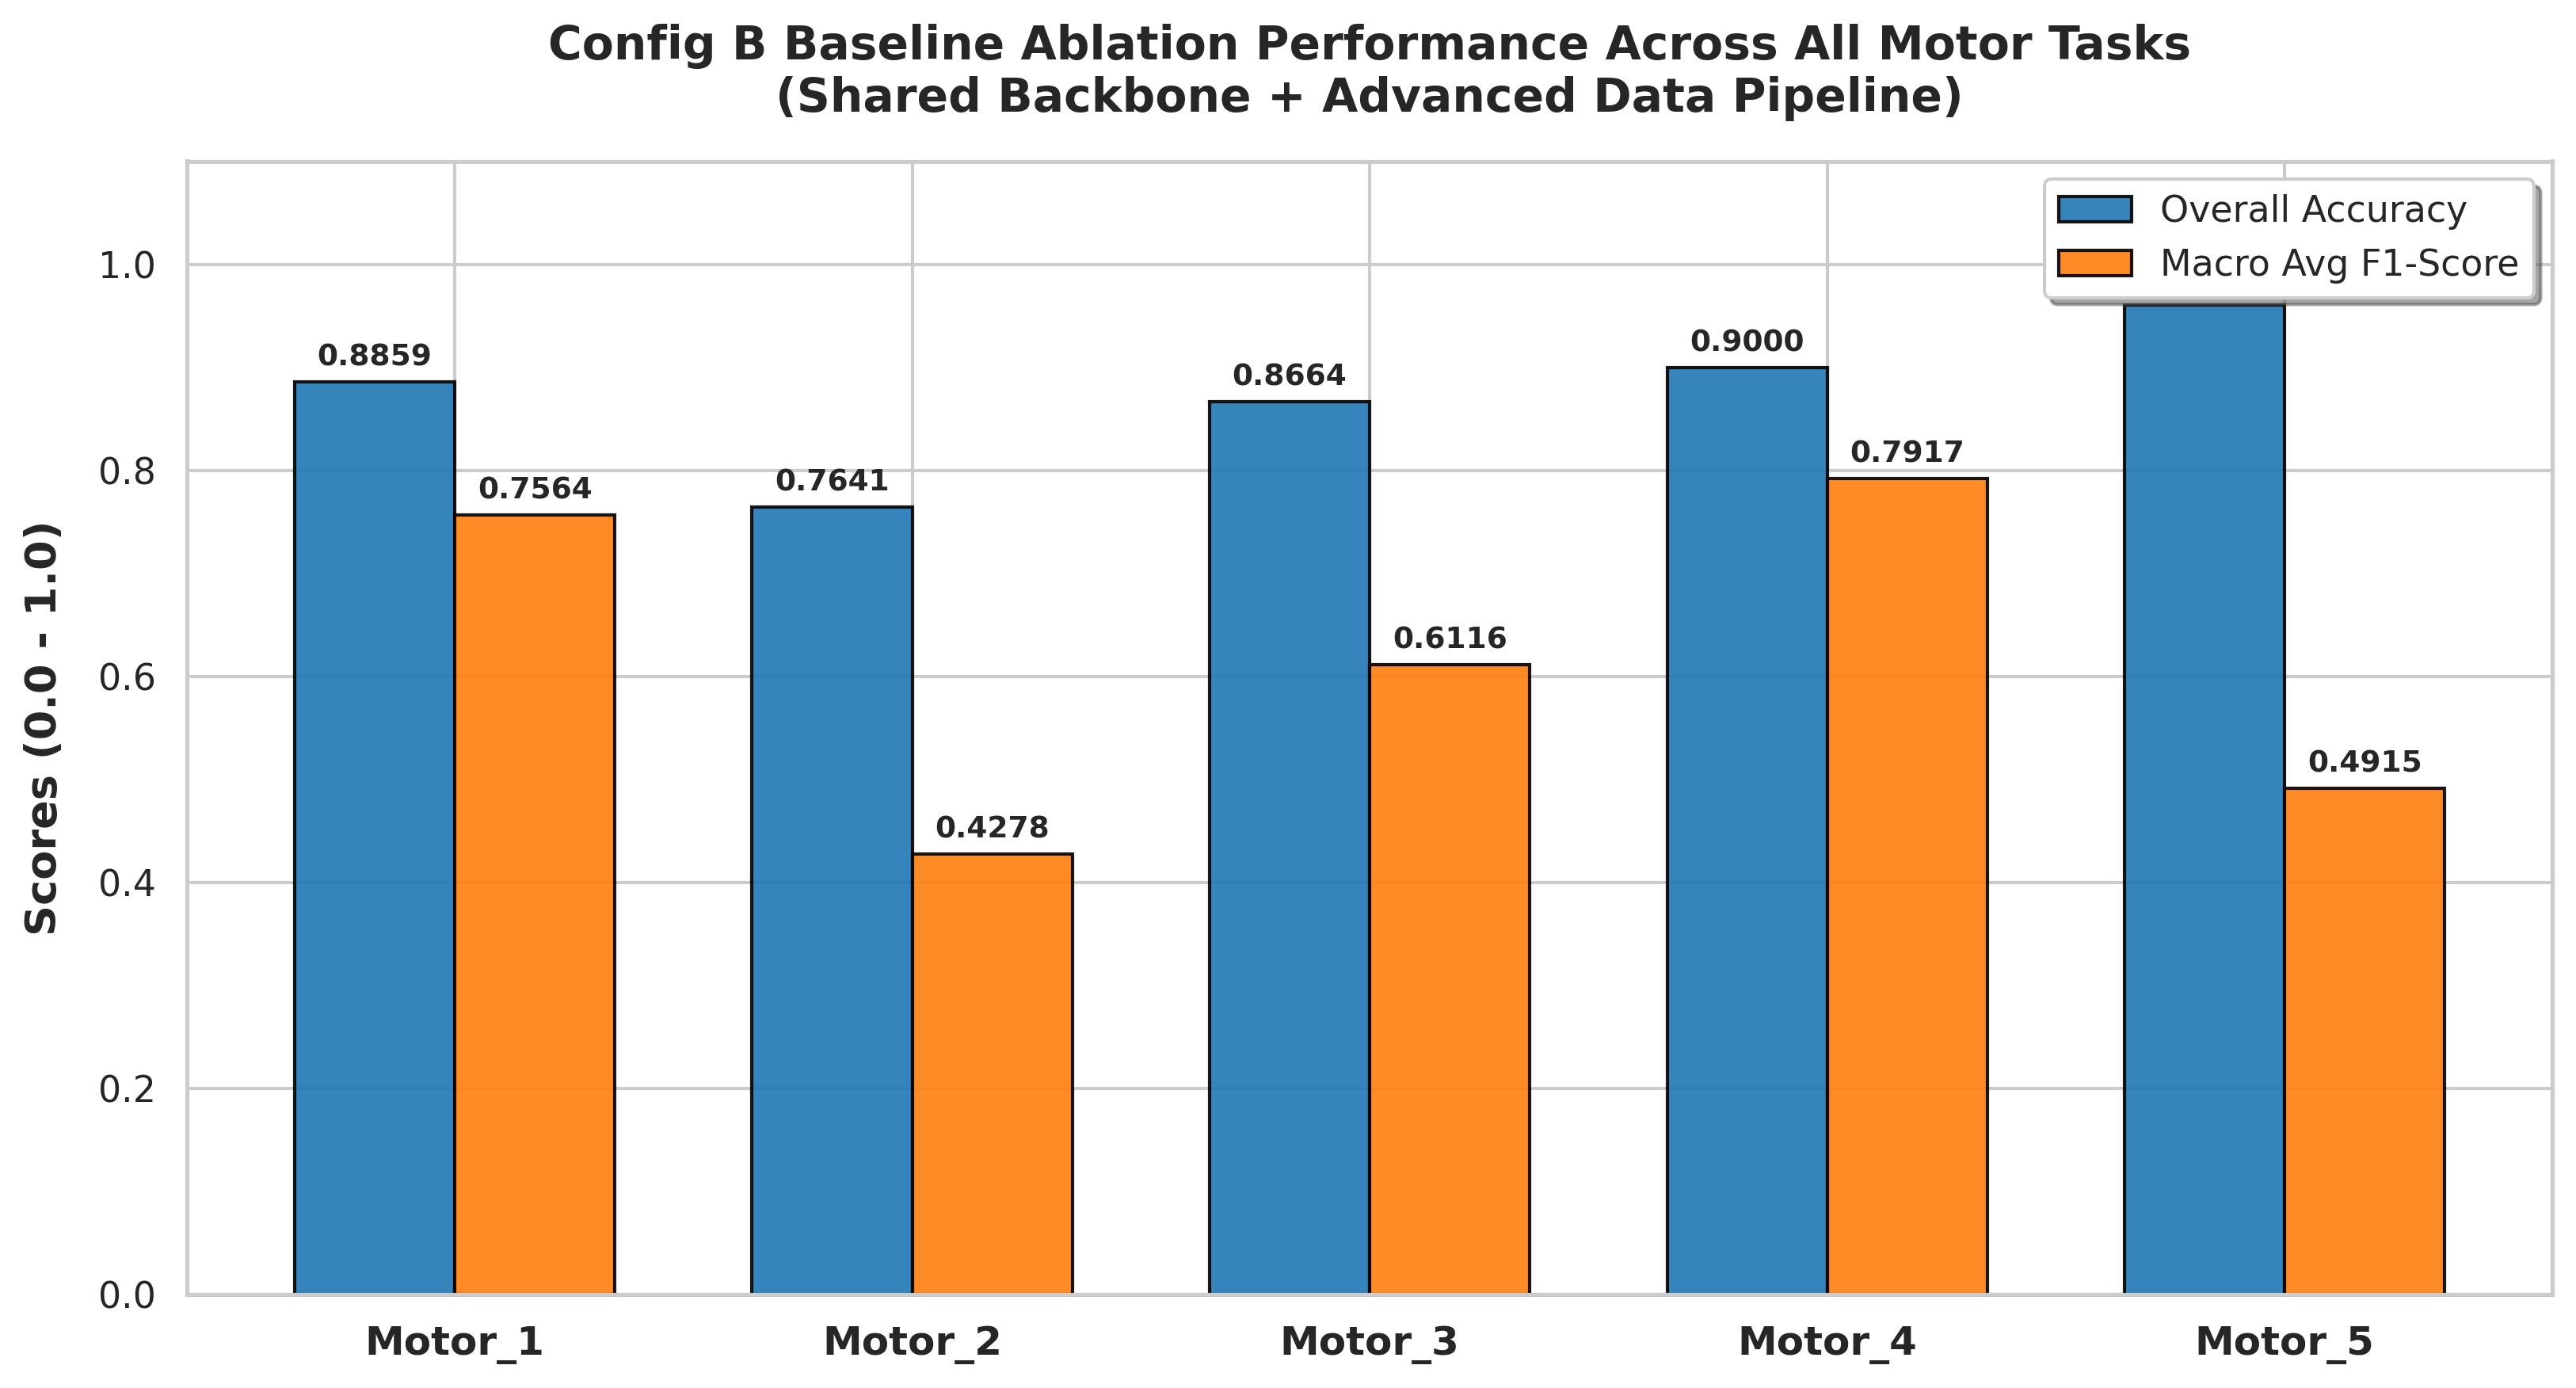

✓ Visualization complete! Figures saved in: /content/drive/MyDrive/Wolfset_Dataset/Results/shared_backbone_config_B_ablation


In [ ]:
# ==============================================================================
# CONFIG B (CELL 8): High-Resolution Visualizations for PPT and Paper
# Output Formats: 300 DPI PNG & Scalable Vector PDF
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

motors = ablation_results_df["Motor Head"].values
macro_f1 = ablation_results_df["Macro Avg F1"].values
accuracy = ablation_results_df["Accuracy"].values

x = np.arange(len(motors))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6), dpi=300) # হাই রেজোলিউশন কনফিগারেশন

rects1 = ax.bar(x - width/2, accuracy, width, label='Overall Accuracy', color='#1f77b4', edgecolor='black', alpha=0.9)
rects2 = ax.bar(x + width/2, macro_f1, width, label='Macro Avg F1-Score', color='#ff7f0e', edgecolor='black', alpha=0.9)

ax.set_ylabel('Scores (0.0 - 1.0)', fontsize=13, fontweight='bold', labelpad=10)
ax.set_title('Config B Baseline Ablation Performance Across All Motor Tasks\n(Shared Backbone + Advanced Data Pipeline)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(motors, fontsize=12, fontweight='bold')
ax.set_ylim(0, 1.1)
ax.legend(loc='upper right', fontsize=11, frameon=True, shadow=True)

# বারের উপর ডেটা ভ্যালু প্রিন্ট করার জন্য লেবেলার
def attach_data_labels(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

attach_data_labels(rects1)
attach_data_labels(rects2)

plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/config_B_performance_comparison.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{RESULT_DIR}/config_B_performance_comparison.pdf", bbox_inches='tight') # ভেক্টর মোড থিসিসের জন্য নিখুঁত
plt.show()

print(f"✓ Visualization complete! Figures saved in: {RESULT_DIR}")